# Шаг 5. Что видит BERT

**Как учили BERT.** GPT (сессия 5) учится угадывать **следующий** токен. BERT учили иначе: в тексте закрывают 15% слов
служебным токеном `[MASK]`, и модель должна угадать закрытое слово, глядя на слова **с обеих сторон**.
Например: «Москва — `[MASK]` России» → «столица». Так модель на миллионах предложений выучивает и язык, и немного знаний о мире.

Потом к обученному BERT приделывают голову для нужной задачи — тон, эмоции, жанр (шаги 2 и 4). Но голова для `[MASK]`
тоже сохранилась, и можно посмотреть, что модель «думает».

In [1]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session05 и session06).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session06")  # здесь лежит common.py; модели скачаются в machine_vision/data/hf
    sys.path.insert(0, os.getcwd())
    !pip install -q transformers

In [2]:
import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F

from common import load_model, load_tokenizer, show

tok = load_tokenizer("bert")
mlm = load_model("bert", "mlm")


@torch.no_grad()
def mask_probs(text):
    """Вероятности всех токенов словаря на месте [MASK]."""
    batch = tok(text, return_tensors="pt")
    pos = (batch["input_ids"][0] == tok.mask_token_id).nonzero()[0, 0]
    return mlm(**batch).logits[0, pos].softmax(-1)


def guess(text, k=6):
    probs = mask_probs(text)
    best = probs.topk(k)
    words = [f"{tok.convert_ids_to_tokens([i])[0]} {p:.0%}" for p, i in zip(best.values.tolist(), best.indices.tolist())]
    print(f"{text:45s} → {', '.join(words)}")

## 1. Угадай слово

Перед запуском угадайте сами, какое слово закрыто, — а потом сравните с моделью.

In [3]:
for text in ["Москва — столица [MASK].", "Я пью чай с [MASK].", "На небе светит яркое [MASK].",
             "Летом мы поехали на [MASK] купаться.", "Мой дядя самых честных [MASK].",
             "Пушкин написал роман «Евгений [MASK]».", "Дважды два равно [MASK].",
             "Учитель поставил мне [MASK] за контрольную."]:
    guess(text)

Москва — столица [MASK].                      → России 16%, Москвы 11%, столицы 6%, Украины 6%, города 4%, страны 4%
Я пью чай с [MASK].                           → сахаром 8%, водой 8%, медом 7%, чаем 6%, молоком 6%, кофе 4%
На небе светит яркое [MASK].                  → небо 29%, солнце 20%, сияние 10%, освещение 8%, пламя 3%, затмение 3%
Летом мы поехали на [MASK] купаться.          → море 5%, остров 5%, улицу 4%, дачу 3%, воду 3%, берег 3%
Мой дядя самых честных [MASK].                → людей 11%, человек 6%, мужчин 2%, детей 1%, героев 1%, парней 1%
Пушкин написал роман «Евгений [MASK]».        → Петрович 5%, Михайлович 5%, Сергеевич 4%, Александрович 4%, Владимирович 4%, Алексеевич 3%
Дважды два равно [MASK].                      → два 3%, нет 2%, погибли 2%, были 2%, дважды 1%, подряд 1%
Учитель поставил мне [MASK] за контрольную.   → ответственность 14%, награду 4%, работу 4%, команду 3%, задачу 2%, контроль 2%


**Обсудим:**
- «столица России», «чай с сахаром», «светит солнце», «на море купаться» — модель выучила частые сочетания слов;
- «Мой дядя самых честных **людей**» — грамматически правильно, но Пушкина модель не помнит: строчка встречалась в текстах слишком редко;
- «Евгений **Петрович**» — забавная и очень показательная ошибка: в обычных текстах после имени чаще всего идёт **отчество**.
  Модель знает статистику текстов, а не литературу;
- «Дважды два равно…» — модель не считает. Она видит слова, а не числа;
- «поставил мне **ответственность**» — у маленькой модели (29 млн весов) знаний немного. Большие модели угадывают гораздо лучше.

## 2. Чему модель научилась у людей: стереотипы

Модель выучила то, что было в текстах, — в том числе **стереотипы**. Сравним вероятности «Он» и «Она» в начале фразы
«`[MASK]` работает врачом.» для разных профессий. Покажем долю «Она»: P(Она) / (P(Он) + P(Она)).

Важная оговорка про русский язык: «медсестрой» — слово женского рода, поэтому «Она» там подсказывает сама грамматика.
А вот «врачом», «инженером», «водителем», «учителем» — одинаково мужского рода, и разница между ними берётся только из текстов.

[MASK] работает медсестрой     P(Он) = 0.063, P(Она) = 0.089, доля «Она» 59%
[MASK] работает воспитателем   P(Он) = 0.126, P(Она) = 0.097, доля «Она» 43%
[MASK] работает врачом         P(Он) = 0.164, P(Она) = 0.104, доля «Она» 39%
[MASK] работает парикмахером   P(Он) = 0.179, P(Она) = 0.101, доля «Она» 36%
[MASK] работает учителем       P(Он) = 0.130, P(Она) = 0.059, доля «Она» 31%
[MASK] работает бухгалтером    P(Он) = 0.113, P(Она) = 0.043, доля «Она» 28%
[MASK] работает секретарём     P(Он) = 0.189, P(Она) = 0.073, доля «Она» 28%
[MASK] работает программистом  P(Он) = 0.098, P(Она) = 0.034, доля «Она» 26%


[MASK] работает строителем     P(Он) = 0.169, P(Она) = 0.052, доля «Она» 23%
[MASK] работает пилотом        P(Он) = 0.129, P(Она) = 0.040, доля «Она» 24%
[MASK] работает водителем      P(Он) = 0.141, P(Она) = 0.032, доля «Она» 18%
[MASK] работает инженером      P(Он) = 0.133, P(Она) = 0.026, доля «Она» 16%


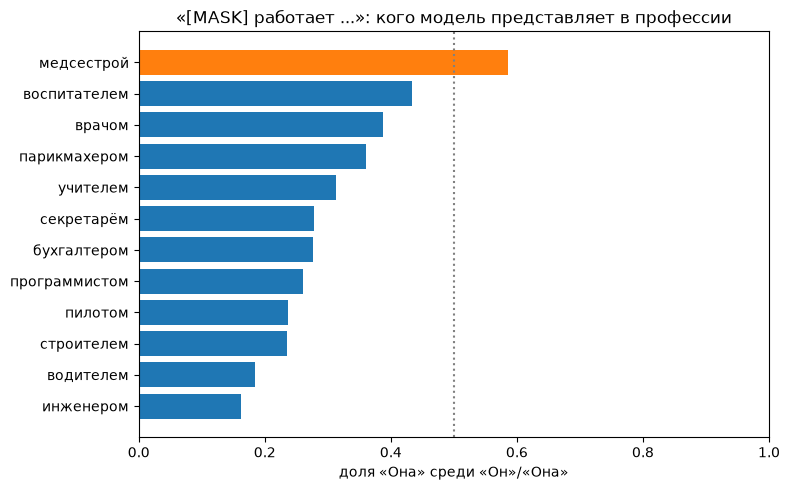

In [4]:
he, she = tok.convert_tokens_to_ids("Он"), tok.convert_tokens_to_ids("Она")
professions = ["медсестрой", "воспитателем", "врачом", "парикмахером", "учителем", "бухгалтером",
               "секретарём", "программистом", "строителем", "пилотом", "водителем", "инженером"]
share = {}
for prof in professions:
    p = mask_probs(f"[MASK] работает {prof}.")
    share[prof] = (p[she] / (p[he] + p[she])).item()
    print(f"[MASK] работает {prof:14s} P(Он) = {p[he]:.3f}, P(Она) = {p[she]:.3f}, доля «Она» {share[prof]:.0%}")

order = sorted(share, key=share.get)
plt.figure(figsize=(8, 5))
plt.barh(order, [share[p] for p in order], color=["tab:orange" if share[p] > 0.5 else "tab:blue" for p in order])
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlim(0, 1)
plt.xlabel("доля «Она» среди «Он»/«Она»")
plt.title("«[MASK] работает ...»: кого модель представляет в профессии")
plt.tight_layout()
plt.savefig("bias.png", dpi=100)
show()

**Почему это важно.** Если такую модель поставить сортировать резюме, она может незаметно «предпочитать» один пол для одних профессий
и другой — для других. Модель не «плохая» и не «хорошая» — она **зеркало** текстов, на которых училась.
Поэтому разработчики больших моделей специально проверяют их на стереотипы и стараются их ослаблять.

## 3. Слово в контексте

В эмбеддинге из сессии 5 у каждого символа был **один** вектор — где бы он ни стоял. А после блоков внимания вектор слова
меняется: слово «посмотрело» на соседей. Поэтому одно и то же слово в разных фразах должно получать разные векторы.

Проверим на многозначных словах: «ключ» (от двери / родник), «лук» (овощ / оружие), «замок» (на двери / дворец).
Для каждого — по три фразы на каждое значение. Слово стоит в **конце** фразы, после поясняющих слов.

Здесь возьмём не rubert-tiny2, а ruGPT-3 из шага 6: у неё 12 слоёв (у rubert-tiny2 всего 3), и эффект виден лучше.
Вектор слова можно достать после **каждого** слоя и посмотреть, как значения расходятся по мере продвижения вглубь сети.

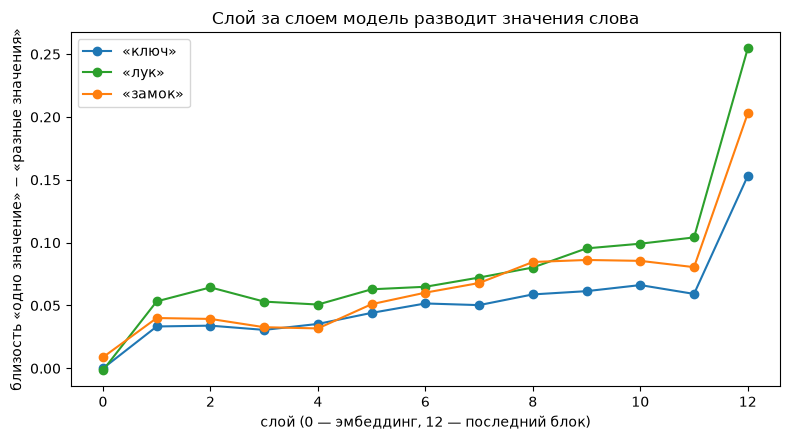

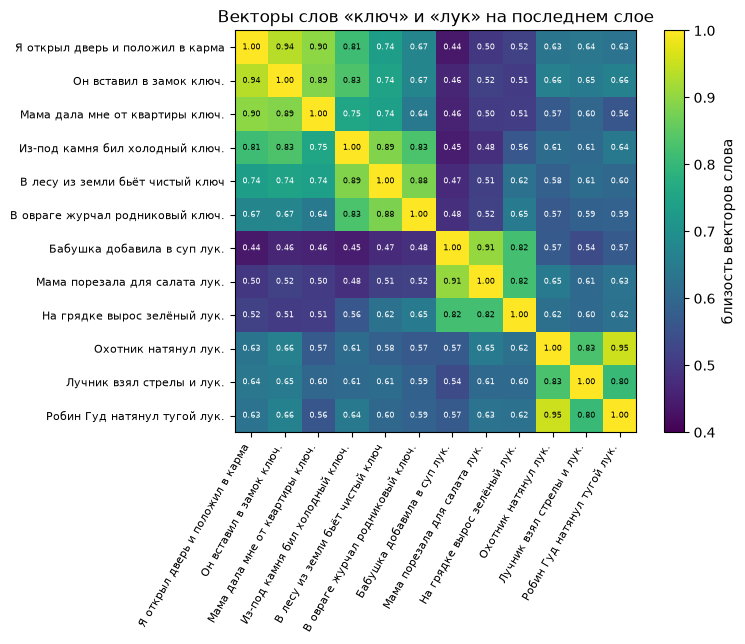

In [5]:
gpt_tok = load_tokenizer("gpt")
gpt = load_model("gpt")

words = {
    "ключ": ["Я открыл дверь и положил в карман ключ.", "Он вставил в замок ключ.", "Мама дала мне от квартиры ключ.",
             "Из-под камня бил холодный ключ.", "В лесу из земли бьёт чистый ключ.", "В овраге журчал родниковый ключ."],
    "лук": ["Бабушка добавила в суп лук.", "Мама порезала для салата лук.", "На грядке вырос зелёный лук.",
            "Охотник натянул лук.", "Лучник взял стрелы и лук.", "Робин Гуд натянул тугой лук."],
    "замок": ["Я закрыл дверь на замок.", "На сейфе сломался замок.", "На двери висел тяжёлый амбарный замок.",
              "Король жил в старинном замке.", "На горе стоит рыцарский замок.", "Над рвом возвышался каменный замок."],
}


@torch.no_grad()
def word_vectors(sentence, word):
    """Векторы слова после каждого слоя: список из 13 векторов (эмбеддинг + 12 блоков)."""
    stem = word[:3]                                       # «замке» тоже найдётся по «зам»; берём последнее вхождение
    start = sentence.rindex(stem)
    end = start + len(stem)
    batch = gpt_tok(sentence, return_tensors="pt", return_offsets_mapping=True)
    offsets = batch.pop("offset_mapping")[0].tolist()
    positions = [i for i, (s, e) in enumerate(offsets) if s < end and e > start]   # токены, задевающие слово
    layers = gpt(**batch, output_hidden_states=True).hidden_states
    return [F.normalize(h[0, positions].mean(0), dim=0) for h in layers]


vectors = {w: [word_vectors(s, w) for s in sentences] for w, sentences in words.items()}

# Близость внутри одного значения и между разными значениями — для каждого слоя
plt.figure(figsize=(8, 4.5))
for w, color in zip(words, ["tab:blue", "tab:green", "tab:orange"]):
    gaps = []
    for layer in range(13):
        M = torch.stack([v[layer] for v in vectors[w]])
        S = M @ M.T
        same = ((S[:3, :3].sum() - 3) / 6 + (S[3:, 3:].sum() - 3) / 6) / 2     # пары с одним значением
        different = S[:3, 3:].mean()                                         # пары с разными значениями
        gaps.append((same - different).item())
    plt.plot(range(13), gaps, marker="o", color=color, label=f"«{w}»")
plt.xlabel("слой (0 — эмбеддинг, 12 — последний блок)")
plt.ylabel("близость «одно значение» − «разные значения»")
plt.title("Слой за слоем модель разводит значения слова")
plt.legend()
plt.tight_layout()
plt.savefig("word_layers.png", dpi=100)
show()

# Подробно: все попарные близости «лука» и «ключа» на последнем слое
examples = [(s, w) for w in ["ключ", "лук"] for s in words[w]]
V = torch.stack([vectors[w][words[w].index(s)][-1] for s, w in examples])
sim = V @ V.T
plt.figure(figsize=(8, 6.5))
plt.imshow(sim, cmap="viridis", vmin=0.4, vmax=1)
plt.colorbar(label="близость векторов слова")
labels = [s[:32] for s, _ in examples]
plt.xticks(range(len(examples)), labels, rotation=60, ha="right", fontsize=8)
plt.yticks(range(len(examples)), labels, fontsize=8)
for i in range(len(examples)):
    for j in range(len(examples)):
        plt.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=6, color="black" if sim[i, j] > 0.8 else "white")
plt.title("Векторы слов «ключ» и «лук» на последнем слое")
plt.tight_layout()
plt.savefig("word_in_context.png", dpi=100)
show()

**Что видно:**
- на слое 0 (эмбеддинг) разница около нуля: вектор «лука» почти один и тот же в любой фразе — как у символов в сессии 5
  (не совсем один из-за эмбеддинга позиции);
- с каждым слоем разница растёт: блоки внимания «подмешивают» к слову соседей, и к последнему слою «лук» в супе
  и «лук» в руках охотника — уже заметно разные векторы;
- самый большой скачок — на последнем слое: он сильнее всего «готовит» вектор к угадыванию следующего слова,
  а после супа и после охоты ждут совсем разных продолжений;
- на тепловой карте видны квадраты 3 × 3: фразы с одним значением ближе друг к другу, чем к фразам с другим.

Именно поэтому модели и нужны слои внимания: без них «лук» был бы просто «лук», и модель не отличила бы суп от охоты.

## Попробуйте сами

1. Придумайте 3 фразы с `[MASK]`, где модель угадывает правильно, и 3 — где ошибается. Что отличает удачные фразы?
2. Добавьте в пункт 2 свои профессии (продавцом, психологом, поваром, директором…). Найдётся ли слово мужского рода,
   у которого доля «Она» больше 50%? Какая профессия у модели самая «мужская»?
3. Проверьте стереотипы по-другому: «`[MASK]` любит играть в футбол», «`[MASK]` любит готовить», «`[MASK]` плачет».
4. Найдите своё многозначное слово (лист, мир, ручка, коса) и проверьте, различает ли модель его значения.
   Подсказка: слово должно стоять после поясняющих слов — GPT видит только то, что слева (маска из сессии 5).
5. Поставьте многозначное слово в **начало** фразы («Лук натянул охотник»). Различает ли теперь GPT значения? Почему?